# Контрольная точка 4
# Задание 1
## Анализ информативности признаков

Данные - US Accidents (March 2023), целевая переменная та же, что в КТ3: `Severity >= 3` ("тяжёлое" ДТП против "нетяжёлого").

В КТ3 модели обучались на 15 колонках (7 числовых + 8 POI-флагов) и упёрлись в ROC-AUC около 0.80. Здесь разбираю весь доступный набор полей и отвечаю на три вопроса: что реально несёт сигнал, что дублирует друг друга и что даёт завышенную оценку из-за утечки.

План:
1. Аудит колонок: пропуски, кардинальность, константы, разная доля пропусков по классам.
2. Фильтры (без модели): mutual information, ANOVA F, chi2, Cramer's V, IV/WoE, одиночный ROC-AUC.
3. Избыточность: ранговые корреляции между признаками, почти одинаковые колонки.
4. Встроенные методы: gain у XGBoost, impurity у случайного леса, permutation importance на отложенной выборке, drop-column для верхушки рейтинга.
5. Обёртка: жадный forward selection по ROC-AUC.
6. Сведение рангов разных методов и проверка на модели: базовый набор КТ3 против отобранного.

Протокол данных наследую из КТ3: одна авария = одна группа `group_id`, дедупликация до одной строки на группу. После дедупликации разбиение по группам совпадает с разбиением по строкам, так что утечка через дубликаты снята на входе.

Полный набор (7.7 млн строк) для перебора методов не нужен: работаю на подвыборке, отобранной по хешу `group_id` (группы целиком, не строки). Самого датасета в репозитории нет, он подтягивается из локального кеша или через kagglehub.

In [1]:
import os
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, chi2_contingency
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import mutual_info_classif, f_classif, chi2
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             f1_score, balanced_accuracy_score)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

In [2]:
SEED = 42
rng = np.random.RandomState(SEED)

# где искать данные (в репозитории датасета нет, он слишком большой)
GROUPED_CANDIDATES = [
    "df_with_groups.csv.gz",
    "KTs/kt3/df_with_groups.csv.gz",
    "../kt3/df_with_groups.csv.gz",
]
RAW_CANDIDATES = [
    r"C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv",
    "US_Accidents_March23.csv",
    "data/US_Accidents_March23.csv",
]

KEEP_PERMILLE = 60      # сколько тысячных долей групп оставляем (60/1000 от 6.77 млн групп)
MAX_ROWS = 450_000
CHUNKSIZE = 400_000

N_MI = 40_000           # mutual information считается на меньшей подвыборке
N_MODEL = 200_000       # обучение XGBoost / RandomForest
N_PERM = 60_000         # permutation importance на тесте
N_DROP = 120_000        # drop-column importance
N_FS_TRAIN = 100_000    # forward selection
N_FS_VALID = 50_000

RUN_DROP_COLUMN = True  # обе тяжёлые части можно выключить, если нужен быстрый прогон
RUN_FORWARD = True

NUM_RAW = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
           "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
           "Start_Lat", "Start_Lng", "End_Lat", "End_Lng"]
BIN_RAW = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit",
           "Railway", "Roundabout", "Station", "Stop", "Traffic_Calming",
           "Traffic_Signal", "Turning_Loop"]
CAT_RAW = ["Source", "State", "City", "County", "Street", "Zipcode", "Country",
           "Timezone", "Airport_Code", "Wind_Direction", "Weather_Condition",
           "Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]
TIME_RAW = ["Start_Time", "End_Time"]

# базовый набор из КТ3, с ним сравниваю в конце
KT3_FEATURES = ["Distance(mi)", "Temperature(F)", "Humidity(%)", "Pressure(in)",
                "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)",
                "Bump", "Crossing", "Junction", "Railway",
                "Station", "Stop", "Traffic_Signal", "Amenity"]

# поля, которые описывают последствия ДТП, а не обстановку на момент ДТП
LEAKAGE_CANDIDATES = ["duration_min", "Distance(mi)", "End_Lat", "End_Lng", "has_end"]

USECOLS = set(NUM_RAW + BIN_RAW + CAT_RAW + TIME_RAW + ["Severity", "group_id"])
print("конфигурация готова, колонок в списке:", len(USECOLS))

конфигурация готова, колонок в списке: 43


In [3]:
# полная загрузка: все колонки исходного CSV, group_id подклеивается по ID из файла КТ3
def pick_path(cands):
    for p in cands:
        if os.path.exists(p):
            return p
    return None


def resolve_raw():
    p = pick_path(RAW_CANDIDATES)
    if p is not None:
        return p
    try:
        import kagglehub
        base = kagglehub.dataset_download("sobhanmoosavi/us-accidents")
        p = os.path.join(base, "US_Accidents_March23.csv")
        return p if os.path.exists(p) else None
    except Exception as e:
        print("kagglehub недоступен:", e)
        return None


raw_path = resolve_raw()
if raw_path is None:
    raise FileNotFoundError(
        "Нужен полный US_Accidents_March23.csv: положите файл рядом или пропишите путь в RAW_CANDIDATES"
    )
groups_path = pick_path(GROUPED_CANDIDATES)
print("источник признаков:", raw_path)
print("источник group_id:", groups_path)

# проход 1: весь CSV чанками, отбор строк по хешу ID
# файл отсортирован по источнику и времени, останавливаться на первых чанках нельзя
parts, total, t0 = [], 0, time.time()
for i, chunk in enumerate(pd.read_csv(raw_path, usecols=lambda c: c in USECOLS or c == "ID",
                                      chunksize=CHUNKSIZE, low_memory=False)):
    total += len(chunk)
    h = pd.util.hash_array(chunk["ID"].to_numpy()) % 1000
    parts.append(chunk.loc[h < KEEP_PERMILLE])
    if i % 5 == 0:
        got = sum(len(p) for p in parts)
        print(f"  чанк {i}: прочитано {total:,}, отобрано {got:,}", flush=True)
raw = pd.concat(parts, ignore_index=True)
del parts
print(f"CSV: всего {total:,} строк, отобрано {len(raw):,} ({time.time() - t0:.1f}s)")

# проход 2: из файла КТ3 нужны только ID и group_id, причём лишь для отобранных строк
gid = None
if groups_path is not None:
    try:
        need = set(raw["ID"])
        gparts = []
        for chunk in pd.read_csv(groups_path, usecols=["ID", "group_id"], chunksize=CHUNKSIZE):
            gparts.append(chunk[chunk["ID"].isin(need)])
        gid = (pd.concat(gparts, ignore_index=True)
                 .drop_duplicates("ID").set_index("ID")["group_id"])
        del gparts, need
    except Exception as e:
        print("ID/group_id из файла КТ3 прочитать не удалось:", e)
        gid = None

if gid is not None:
    raw["group_id"] = raw["ID"].map(gid)
    del gid
    lost = int(raw["group_id"].isna().sum())
    raw = raw[raw["group_id"].notna()].reset_index(drop=True)
    raw["group_id"] = raw["group_id"].astype("int64")
    print(f"group_id подклеен, строк без пары отброшено: {lost}")
else:
    try:
        sys.path.append(os.path.abspath("../../.."))
        from KTs.kt3.analyze_sources import link_duplicates
        raw["group_id"] = link_duplicates(raw, radius_m=150.0, time_h=6.0)
        print("group_id пересчитан на подвыборке (приближённо, связи за её пределами не видны)")
    except Exception as e:
        print("group_id пересчитать не удалось:", e)
        raw["group_id"] = np.arange(len(raw))

raw = raw.drop(columns="ID")
if "Severity" not in raw.columns:
    raise KeyError("в источнике нет колонки Severity")

# отбор шёл по строкам, поэтому группа может попасть частично;
# после дедупликации от аварии остаётся одна строка, утечки между train и test нет
if len(raw) > MAX_ROWS:
    gs = raw["group_id"].value_counts()
    order = rng.permutation(gs.index.to_numpy())
    n_g = int((gs.loc[order].cumsum() <= MAX_ROWS).sum())
    raw = raw[raw["group_id"].isin(set(order[:n_g]))].reset_index(drop=True)
    print(f"усечено до {len(raw):,} строк ({n_g:,} групп)")

print("колонок в выборке:", raw.shape[1])
print(sorted(raw.columns))

источник признаков: C:\Users\musai\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv
источник group_id: ../kt3/df_with_groups.csv.gz
  чанк 0: прочитано 400,000, отобрано 23,922
  чанк 5: прочитано 2,400,000, отобрано 143,693
  чанк 10: прочитано 4,400,000, отобрано 263,895
  чанк 15: прочитано 6,400,000, отобрано 383,988
CSV: всего 7,728,394 строк, отобрано 463,800 (43.0s)
group_id подклеен, строк без пары отброшено: 0
усечено до 450,000 строк (443,663 групп)
колонок в выборке: 43
['Airport_Code', 'Amenity', 'Astronomical_Twilight', 'Bump', 'City', 'Civil_Twilight', 'Country', 'County', 'Crossing', 'Distance(mi)', 'End_Lat', 'End_Lng', 'End_Time', 'Give_Way', 'Humidity(%)', 'Junction', 'Nautical_Twilight', 'No_Exit', 'Precipitation(in)', 'Pressure(in)', 'Railway', 'Roundabout', 'Severity', 'Source', 'Start_Lat', 'Start_Lng', 'Start_Time', 'State', 'Station', 'Stop', 'Street', 'Sunrise_Sunset', 'Temperature(F)', 'Timezone', 'Traffic_Calming', 'Tr

In [4]:
def to_binary(s):
    if s.dtype == bool:
        return s.astype(float)
    mapping = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0,
               "TRUE": 1.0, "FALSE": 0.0, 1: 1.0, 0: 0.0, 1.0: 1.0, 0.0: 0.0}
    return s.astype("object").map(mapping).astype(float)


def to_dt(s):
    out = pd.to_datetime(s, errors="coerce", format="%Y-%m-%d %H:%M:%S")
    bad = out.isna() & s.notna()
    if bad.any():
        try:
            out.loc[bad] = pd.to_datetime(s[bad], errors="coerce", format="mixed")
        except (TypeError, ValueError):
            out.loc[bad] = pd.to_datetime(s[bad], errors="coerce")
    return out


t0 = time.time()
present = [c for c in NUM_RAW + BIN_RAW + CAT_RAW + TIME_RAW if c in raw.columns]
agg = {c: "first" for c in present}
agg["Severity"] = "median"
df = raw.sort_values("group_id").groupby("group_id", as_index=False).agg(agg)
del raw
df["y"] = (df["Severity"] >= 3).astype(int)
print(f"дедупликация: {len(df):,} аварий, доля тяжёлых {df['y'].mean():.4f} "
      f"({time.time() - t0:.1f}s)")

num_features = [c for c in NUM_RAW if c in df.columns]
bin_features = [c for c in BIN_RAW if c in df.columns]
cat_features = [c for c in CAT_RAW if c in df.columns]
for c in bin_features:
    df[c] = to_binary(df[c])

derived_num, derived_bin = [], []
if "Start_Time" in df.columns:
    start = to_dt(df["Start_Time"])
    df["hour"] = start.dt.hour
    df["month"] = start.dt.month
    df["dow"] = start.dt.dayofweek
    df["is_weekend"] = (df["dow"] >= 5).astype(float)
    derived_num += ["hour", "month", "dow"]
    derived_bin += ["is_weekend"]
    if "End_Time" in df.columns:
        end = to_dt(df["End_Time"])
        df["duration_min"] = ((end - start).dt.total_seconds() / 60.0).clip(0, 7 * 24 * 60)
        derived_num += ["duration_min"]
    del start
if "End_Lat" in df.columns:
    df["has_end"] = df["End_Lat"].notna().astype(float)
    derived_bin += ["has_end"]

# индикаторы пропусков: в погодных полях пропуск сам по себе может быть сигналом
na_flags = []
for c in ["Temperature(F)", "Humidity(%)", "Pressure(in)",
          "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]:
    if c in df.columns and df[c].isna().mean() > 0.02:
        name = "na_" + c
        df[name] = df[c].isna().astype(float)
        na_flags.append(name)

num_features += derived_num
bin_features += derived_bin + na_flags
print("числовых:", len(num_features), "| бинарных:", len(bin_features),
      "| категориальных:", len(cat_features))

дедупликация: 443,663 аварий, доля тяжёлых 0.1967 (1.0s)
числовых: 15 | бинарных: 20 | категориальных: 15


константы (выбрасываю): ['Turning_Loop', 'Country']
почти константы (оставляю в матрице, но не беру в отбор): ['Bump', 'Give_Way', 'Roundabout', 'No_Exit', 'Traffic_Calming']


,feature,kind,missing_pct,nunique,top_share_pct,miss_pos_pct,miss_neg_pct,miss_gap_pp
0,End_Lng,num,44.57,201165,44.57,76.82,36.67,40.15
1,End_Lat,num,44.57,200281,44.57,76.82,36.67,40.15
2,Precipitation(in),num,28.82,172,64.26,47.23,24.31,22.92
3,Wind_Speed(mph),num,7.46,96,12.31,11.33,6.52,4.81
4,Visibility(mi),num,2.31,57,78.46,2.62,2.23,0.39
5,Humidity(%),num,2.27,100,3.72,2.34,2.26,0.08
6,Wind_Direction,cat,2.27,24,12.31,2.04,2.33,-0.29
7,Weather_Condition,cat,2.27,106,32.84,2.63,2.18,0.45
8,Temperature(F),num,2.13,704,2.21,2.22,2.11,0.11
9,Pressure(in),num,1.83,990,1.83,1.94,1.80,0.14


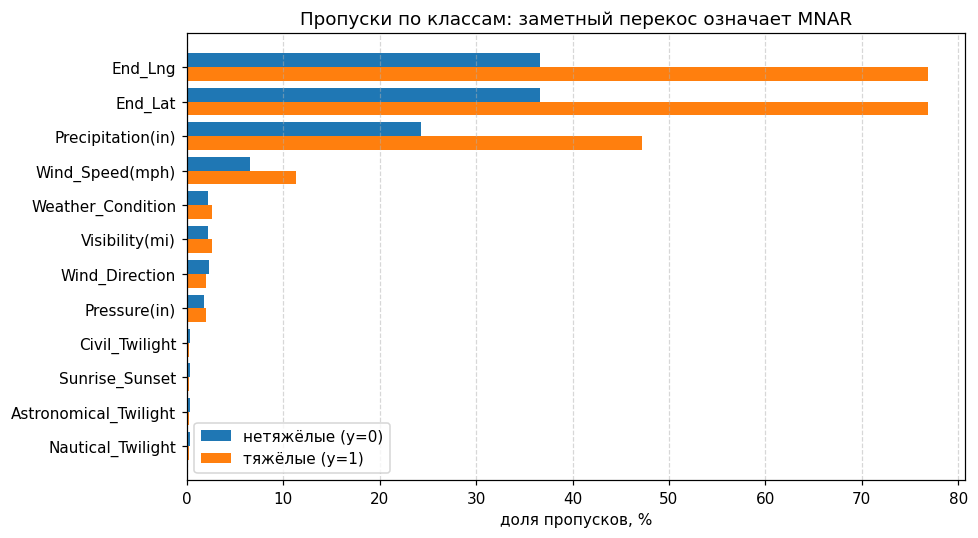

In [5]:
def audit_features(frame, cols, y):
    rows = []
    for c in cols:
        s = frame[c]
        vc = s.value_counts(dropna=False, normalize=True)
        kind = "cat" if c in cat_features else ("bin" if c in bin_features else "num")
        rows.append({
            "feature": c,
            "kind": kind,
            "missing_pct": round(100 * s.isna().mean(), 2),
            "nunique": int(s.nunique(dropna=True)),
            "top_share_pct": round(100 * vc.iloc[0], 2),
            "miss_pos_pct": round(100 * s[y == 1].isna().mean(), 2),
            "miss_neg_pct": round(100 * s[y == 0].isna().mean(), 2),
        })
    out = pd.DataFrame(rows)
    out["miss_gap_pp"] = (out["miss_pos_pct"] - out["miss_neg_pct"]).round(2)
    return out.sort_values("missing_pct", ascending=False).reset_index(drop=True)


all_features = num_features + bin_features + cat_features
audit = audit_features(df, all_features, df["y"])
const_cols = audit.loc[audit["nunique"] <= 1, "feature"].tolist()
quasi_cols = audit.loc[(audit["top_share_pct"] >= 99.5) & (audit["nunique"] > 1), "feature"].tolist()

print("константы (выбрасываю):", const_cols)
print("почти константы (оставляю в матрице, но не беру в отбор):", quasi_cols)
audit.to_csv("task1_audit.csv", index=False, encoding="utf-8-sig")
display(audit.head(20))

num_features = [c for c in num_features if c not in const_cols]
bin_features = [c for c in bin_features if c not in const_cols]
cat_features = [c for c in cat_features if c not in const_cols]

miss_top = audit.sort_values("miss_gap_pp", key=np.abs, ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5))
ypos = np.arange(len(miss_top))
ax.barh(ypos - 0.2, miss_top["miss_neg_pct"], height=0.4, label="нетяжёлые (y=0)")
ax.barh(ypos + 0.2, miss_top["miss_pos_pct"], height=0.4, label="тяжёлые (y=1)")
ax.set_yticks(ypos, miss_top["feature"])
ax.invert_yaxis()
ax.set_xlabel("доля пропусков, %")
ax.set_title("Пропуски по классам: заметный перекос означает MNAR")
ax.legend()
ax.grid(axis="x", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("task1_missing_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# после дедупликации одна строка = одна авария = одна группа,
# поэтому стратифицированное разбиение по строкам эквивалентно разбиению по группам
dtr, dte = train_test_split(df, test_size=0.25, stratify=df["y"], random_state=SEED)
dtr = dtr.reset_index(drop=True)
dte = dte.reset_index(drop=True)
ytr, yte = dtr["y"], dte["y"]
print(f"train {len(dtr):,} (pos {ytr.mean():.4f}) | test {len(dte):,} (pos {yte.mean():.4f})")


def fit_te(s, y, m=30):
    prior = float(np.mean(y))
    key = s.astype("object").where(s.notna(), "__na__")
    g = pd.DataFrame({"k": key.to_numpy(), "y": np.asarray(y)}).groupby("k")["y"].agg(["sum", "count"])
    return ((g["sum"] + m * prior) / (g["count"] + m)).to_dict(), prior


def apply_te(s, mapping, prior):
    key = s.astype("object").where(s.notna(), "__na__")
    return key.map(mapping).fillna(prior).astype(float).to_numpy()


def build_features(dtr, dte, ytr, n_splits=5, m=30):
    Xtr = pd.DataFrame(index=dtr.index)
    Xte = pd.DataFrame(index=dte.index)

    for c in num_features:
        v = pd.to_numeric(dtr[c], errors="coerce")
        med = float(v.median()) if v.notna().any() else 0.0
        Xtr[c] = v.fillna(med).astype("float32")
        Xte[c] = pd.to_numeric(dte[c], errors="coerce").fillna(med).astype("float32")

    for c in bin_features:
        # пропуск флага трактую как "объекта нет", это допущение
        Xtr[c] = to_binary(dtr[c]).fillna(0.0).astype("float32")
        Xte[c] = to_binary(dte[c]).fillna(0.0).astype("float32")

    # категориальные - сглаженный target encoding, на train строго out-of-fold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for c in cat_features:
        oof = np.zeros(len(dtr), dtype=float)
        for tr, va in skf.split(np.zeros(len(dtr)), ytr):
            mp, pr = fit_te(dtr[c].iloc[tr], ytr.iloc[tr], m=m)
            oof[va] = apply_te(dtr[c].iloc[va], mp, pr)
        mp, pr = fit_te(dtr[c], ytr, m=m)
        Xtr[c] = oof.astype("float32")
        Xte[c] = apply_te(dte[c], mp, pr).astype("float32")
    return Xtr, Xte


t0 = time.time()
Xtr, Xte = build_features(dtr, dte, ytr)
feat_names = list(Xtr.columns)
print(f"матрица: train {Xtr.shape}, test {Xte.shape} ({time.time() - t0:.1f}s)")

train 332,747 (pos 0.1967) | test 110,916 (pos 0.1967)
матрица: train (332747, 48), test (110916, 48) (6.2s)


In [7]:
def cramers_v(s, y):
    ct = pd.crosstab(s.astype("object").where(s.notna(), "__na__"), y)
    if min(ct.shape) < 2:
        return 0.0
    chi2v = chi2_contingency(ct, correction=False)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = chi2v / n
    # поправка на смещение, иначе высокая кардинальность завышает V
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2c / den)) if den > 0 else 0.0


def rank_auc(x, y):
    x = np.asarray(x, dtype=float)
    ok = np.isfinite(x)
    x, y = x[ok], np.asarray(y)[ok]
    n1 = int(y.sum())
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(x)
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def make_bins(s, bins=10, categorical=False):
    if categorical:
        key = s.astype("object").where(s.notna(), "__na__")
        vc = key.value_counts()
        if len(vc) > 20:
            thr = max(50, int(0.005 * len(key)))
            rare = vc[vc < thr].index
            key = key.where(~key.isin(rare), "__other__")
        return np.asarray(key)
    x = pd.to_numeric(s, errors="coerce")
    if x.nunique(dropna=True) <= 1:
        return np.asarray(["__one__"] * len(x))
    try:
        b = pd.qcut(x, q=bins, duplicates="drop")
    except ValueError:
        b = pd.cut(x, bins=bins)
    return np.asarray(b.astype("object").where(x.notna(), "__na__"))


def woe_iv(key, y):
    g = pd.DataFrame({"k": np.asarray(key), "y": np.asarray(y)}).groupby("k")["y"].agg(["count", "sum"])
    bad = g["sum"].to_numpy(float) + 0.5
    good = (g["count"] - g["sum"]).to_numpy(float) + 0.5
    pb, pg = bad / bad.sum(), good / good.sum()
    g["woe"] = np.log(pb / pg)
    g["iv_part"] = (pb - pg) * g["woe"]
    g["share"] = g["count"] / g["count"].sum()
    g["pos_rate"] = g["sum"] / g["count"]
    return float(g["iv_part"].sum()), g.sort_values("woe")


t0 = time.time()
res = pd.DataFrame(index=feat_names)

fv, fp = f_classif(Xtr[num_features], ytr)
res.loc[num_features, "anova_F"] = fv
res.loc[num_features, "anova_p"] = fp

cv, cp = chi2(Xtr[bin_features], ytr)
res.loc[bin_features, "chi2"] = cv
res.loc[bin_features, "chi2_p"] = cp

for c in cat_features:
    res.loc[c, "cramers_v"] = cramers_v(dtr[c], ytr)

res["auc_single"] = [rank_auc(Xtr[c].to_numpy(), ytr.to_numpy()) for c in feat_names]
res["auc_strength"] = (res["auc_single"] - 0.5).abs()

iv_vals, bin_cache = [], {}
for c in feat_names:
    is_cat = (c in cat_features) or (c in bin_features)
    key = make_bins(dtr[c], categorical=is_cat)
    bin_cache[c] = key
    iv_vals.append(woe_iv(key, ytr)[0])
res["iv"] = iv_vals

print(f"фильтры без MI посчитаны за {time.time() - t0:.1f}s")
res.sort_values("iv", ascending=False).head(15).round(4)

фильтры без MI посчитаны за 9.1s


,anova_F,anova_p,chi2,chi2_p,cramers_v,auc_single,auc_strength,iv
End_Lng,5293.6491,0.0000,NaN,NaN,NaN,0.5241,0.0241,0.8334
End_Lat,562.9693,0.0000,NaN,NaN,NaN,0.5317,0.0317,0.7926
has_end,NaN,NaN,15406.6461,0.0,NaN,0.2985,0.2015,0.7064
Source,NaN,NaN,NaN,NaN,0.3223,0.7015,0.2015,0.7064
duration_min,448.1087,0.0000,NaN,NaN,NaN,0.3495,0.1505,0.4914
Distance(mi),1.0637,0.3024,NaN,NaN,NaN,0.3802,0.1198,0.3844
Weather_Condition,NaN,NaN,NaN,NaN,0.2027,0.6361,0.1361,0.2439
Precipitation(in),53.2634,0.0000,NaN,NaN,NaN,0.5087,0.0087,0.2349
na_Precipitation(in),NaN,NaN,9584.1430,0.0,NaN,0.6146,0.1146,0.2349
County,NaN,NaN,NaN,NaN,0.2984,0.7007,0.2007,0.2144


mutual information на 40,000 строках: 3.1s
WoE-разбиение самого сильного по IV признака: End_Lng


,count,sum,woe,iv_part,share,pos_rate
k,,,,,,
"(-121.453, -118.237]",18444,610,-1.9676,0.1129,0.0554,0.0331
"(-118.237, -117.111]",18445,611,-1.9660,0.1128,0.0554,0.0331
"(-82.753, -80.886]",18445,925,-1.5338,0.0788,0.0554,0.0501
"(-124.513, -121.453]",18446,1004,-1.4474,0.0722,0.0554,0.0544
"(-80.886, -78.865]",18445,1217,-1.2428,0.0570,0.0554,0.0660
"(-96.689, -88.15]",18445,1712,-0.8725,0.0318,0.0554,0.0928
"(-76.235, -67.843]",18445,1968,-0.7177,0.0227,0.0554,0.1067
"(-78.865, -76.235]",18445,1968,-0.7177,0.0227,0.0554,0.1067
"(-117.111, -96.689]",18445,2013,-0.6924,0.0213,0.0554,0.1091


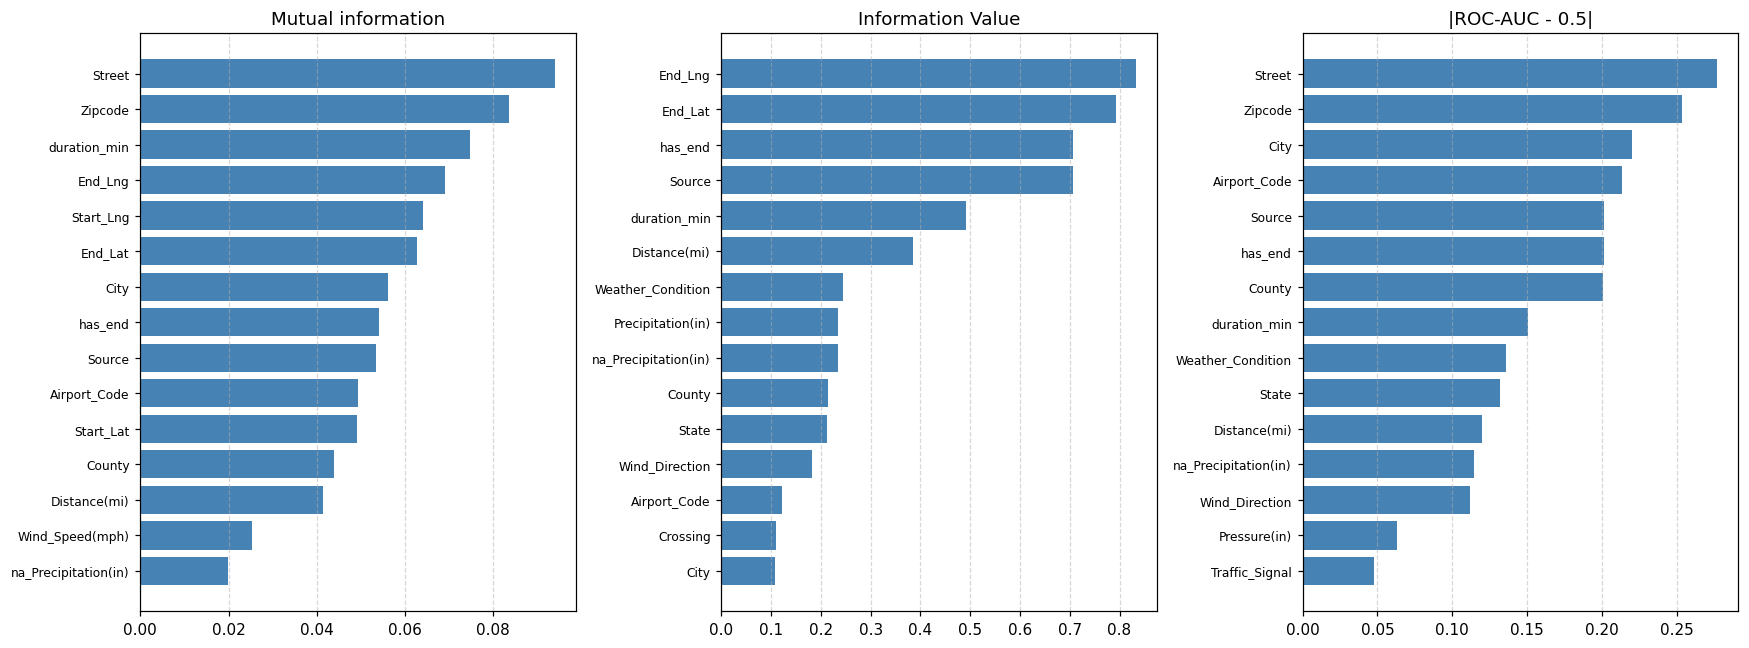

In [8]:
t0 = time.time()
mi_idx = rng.choice(len(Xtr), size=min(N_MI, len(Xtr)), replace=False)
disc = np.array([c in bin_features for c in feat_names])
res["mi"] = mutual_info_classif(Xtr.iloc[mi_idx].to_numpy(), ytr.iloc[mi_idx].to_numpy(),
                                discrete_features=disc, n_neighbors=3, random_state=SEED)
print(f"mutual information на {len(mi_idx):,} строках: {time.time() - t0:.1f}s")

res = res.join(audit.set_index("feature")[["kind", "missing_pct", "nunique", "miss_gap_pp"]])
res.index.name = "feature"
res.to_csv("task1_filters.csv", encoding="utf-8-sig")

top_iv = res["iv"].idxmax()
iv_tab = woe_iv(bin_cache[top_iv], ytr)[1]
print(f"WoE-разбиение самого сильного по IV признака: {top_iv}")
display(iv_tab.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, col, title in zip(axes, ["mi", "iv", "auc_strength"],
                          ["Mutual information", "Information Value", "|ROC-AUC - 0.5|"]):
    s = res[col].sort_values(ascending=False).head(15)[::-1]
    ax.barh(np.arange(len(s)), s.to_numpy(), color="steelblue")
    ax.set_yticks(np.arange(len(s)), s.index, fontsize=8)
    ax.set_title(title)
    ax.grid(axis="x", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("task1_filter_top.png", dpi=150, bbox_inches="tight")
plt.show()

пар с |rho| >= 0.9: 2
  na_Temperature(F)      na_Humidity(%)         +0.964
  Nautical_Twilight      Astronomical_Twilight  +0.918

кандидаты на удаление как дубли:
  na_Temperature(F)      -> дублирует na_Humidity(%)
  Astronomical_Twilight  -> дублирует Nautical_Twilight

доля совпадающих значений у колонок освещённости:


,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
Sunrise_Sunset,1.0000,0.9533,0.9047,0.8643
Civil_Twilight,0.9533,1.0000,0.9513,0.9109
Nautical_Twilight,0.9047,0.9513,1.0000,0.9595
Astronomical_Twilight,0.8643,0.9109,0.9595,1.0000


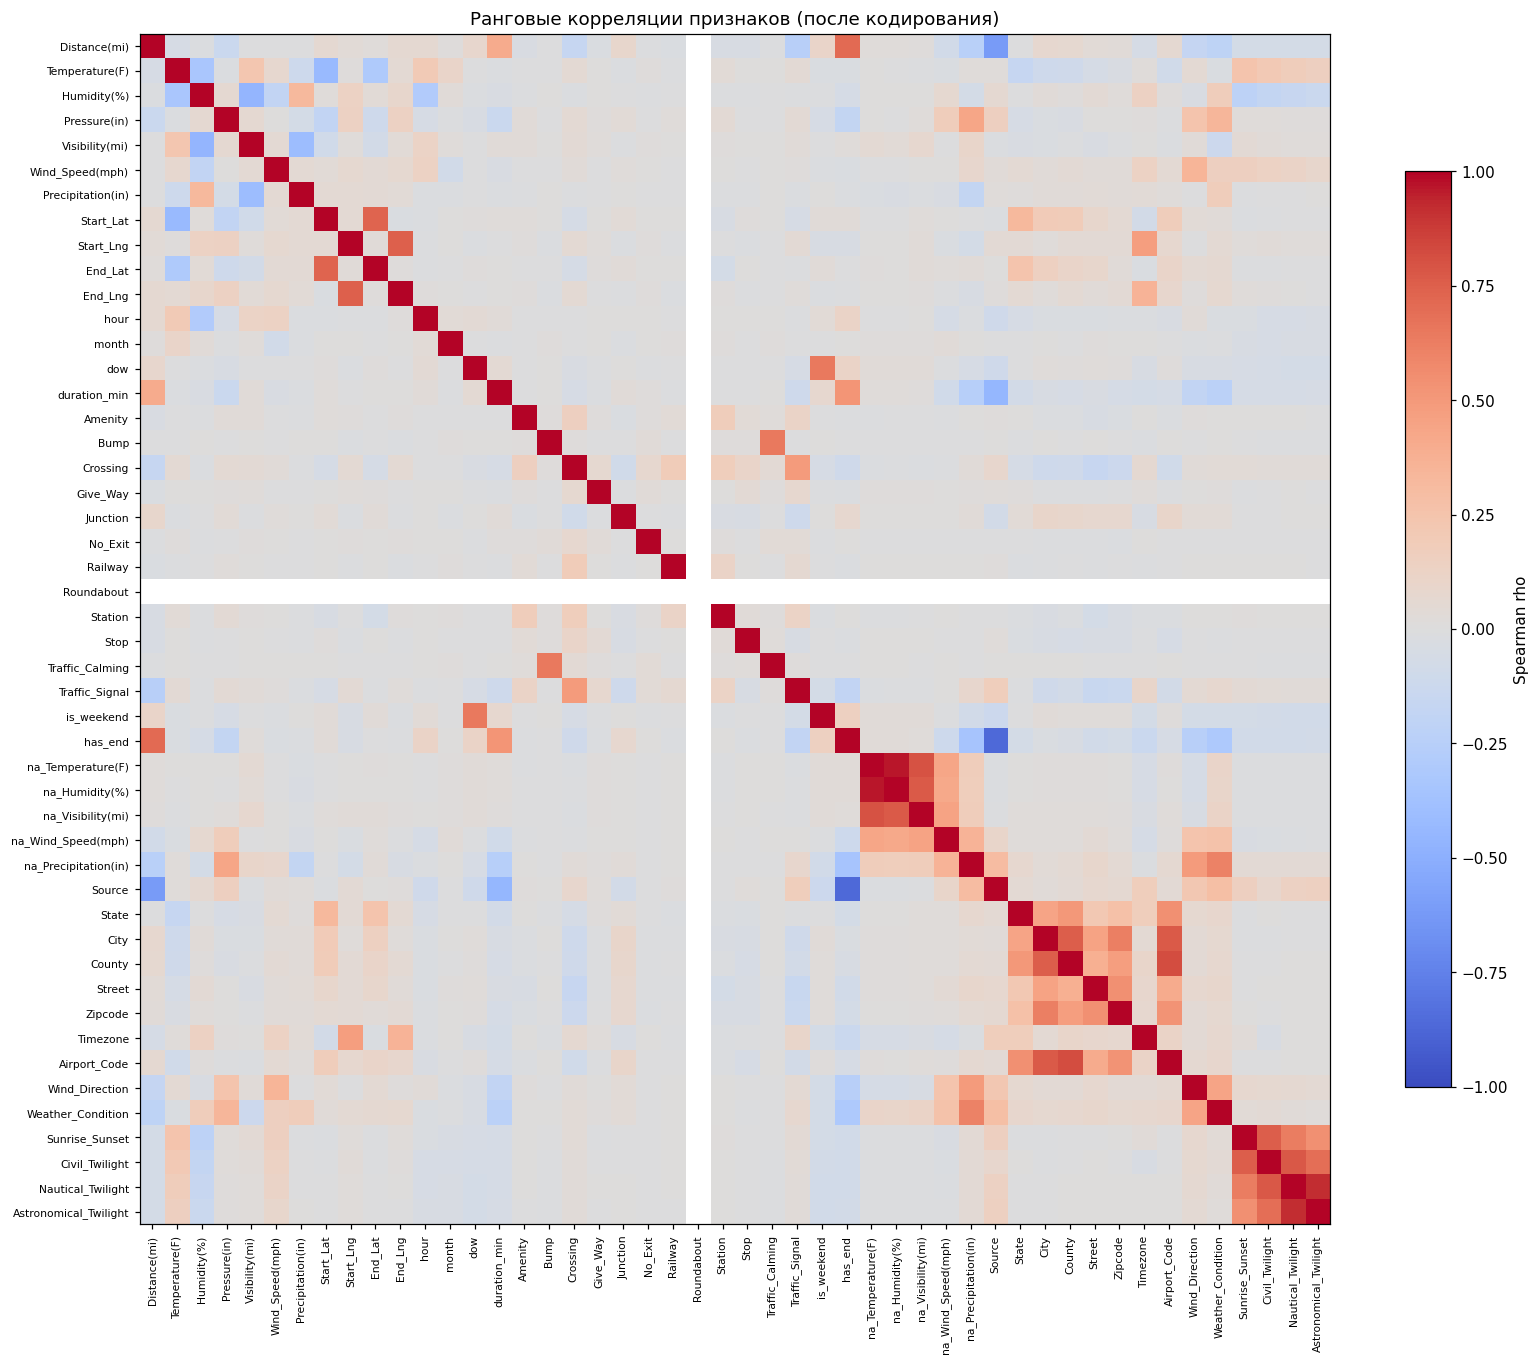

In [9]:
corr_idx = rng.choice(len(Xtr), size=min(30_000, len(Xtr)), replace=False)
corr = Xtr.iloc[corr_idx].corr(method="spearman")

pairs = []
for i, a in enumerate(feat_names):
    for b in feat_names[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) >= 0.9:
            pairs.append((a, b, round(float(r), 3)))
pairs = sorted(pairs, key=lambda t: -abs(t[2]))
print(f"пар с |rho| >= 0.9: {len(pairs)}")
for a, b, r in pairs[:20]:
    print(f"  {a:22s} {b:22s} {r:+.3f}")

# из каждой пары оставляю того, у кого выше MI
keep, redundant = [], {}
for f in res["mi"].sort_values(ascending=False).index:
    dup = next((k for k in keep if abs(corr.loc[f, k]) >= 0.9), None)
    if dup is None:
        keep.append(f)
    else:
        redundant[f] = dup
print("\nкандидаты на удаление как дубли:")
for f, k in redundant.items():
    print(f"  {f:22s} -> дублирует {k}")

light = [c for c in ["Sunrise_Sunset", "Civil_Twilight", "Nautical_Twilight", "Astronomical_Twilight"]
         if c in dtr.columns]
if len(light) > 1:
    agree = pd.DataFrame(index=light, columns=light, dtype=float)
    for a in light:
        for b in light:
            agree.loc[a, b] = (dtr[a].fillna("NA") == dtr[b].fillna("NA")).mean()
    print("\nдоля совпадающих значений у колонок освещённости:")
    display(agree.round(4))

fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(feat_names)), feat_names, rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(feat_names)), feat_names, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman rho")
ax.set_title("Ранговые корреляции признаков (после кодирования)")
plt.tight_layout()
plt.savefig("task1_corr.png", dpi=150, bbox_inches="tight")
plt.show()

XGBoost: test ROC-AUC = 0.9458 (1.6s)
RandomForest: test ROC-AUC = 0.9355 (7.2s)
permutation importance: 10.8s
drop-column по top-10: 8.4s (базовый ROC-AUC 0.9426)


,perm_auc,perm_std,xgb_gain,rf_impurity,mi,iv
feature,,,,,,
Street,0.0476,0.0006,0.0754,0.2263,0.0940,0.0599
has_end,0.0449,0.0009,0.5382,0.0983,0.0540,0.7064
duration_min,0.0375,0.0008,0.0175,0.0457,0.0747,0.4914
Zipcode,0.0316,0.0006,0.0285,0.1542,0.0836,0.0000
Distance(mi),0.0114,0.0003,0.0100,0.0441,0.0415,0.3844
End_Lng,0.0057,0.0003,0.0110,0.0321,0.0690,0.8334
hour,0.0040,0.0001,0.0081,0.0108,0.0037,0.0028
Source,0.0034,0.0002,0.0365,0.0884,0.0535,0.7064
State,0.0033,0.0001,0.0081,0.0147,0.0160,0.2113


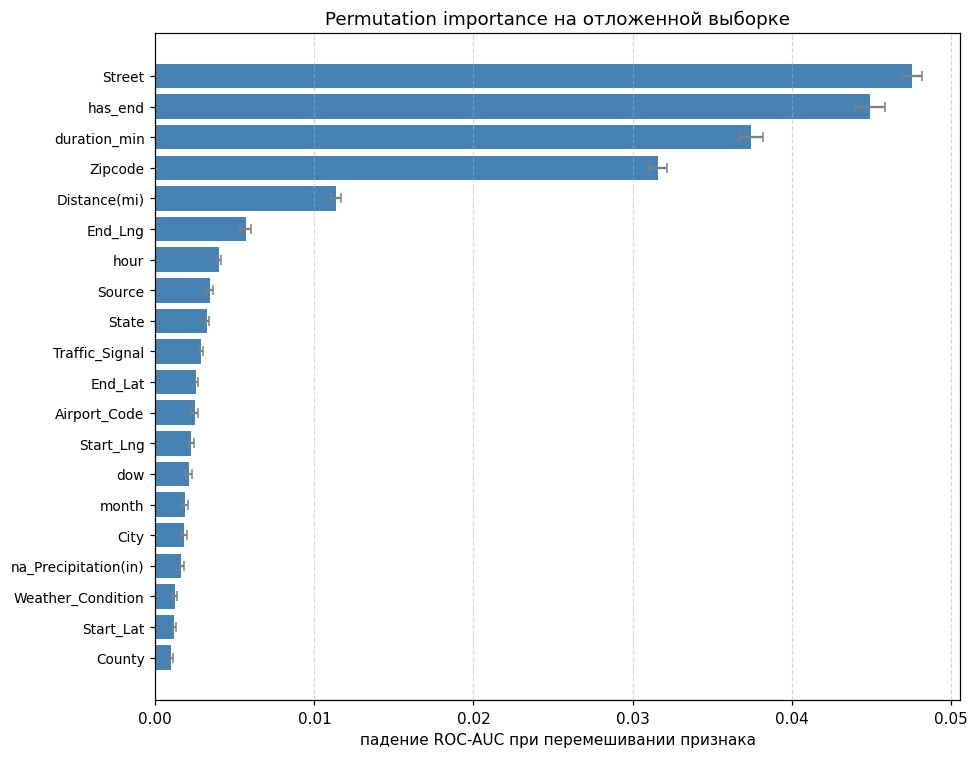

In [10]:
m_idx = rng.choice(len(Xtr), size=min(N_MODEL, len(Xtr)), replace=False)
Xm, ym = Xtr.iloc[m_idx], ytr.iloc[m_idx]
p_idx = rng.choice(len(Xte), size=min(N_PERM, len(Xte)), replace=False)
Xp, yp = Xte.iloc[p_idx], yte.iloc[p_idx]

xgb_params = dict(tree_method="hist", n_estimators=300, max_depth=6, learning_rate=0.1,
                  subsample=0.8, colsample_bytree=0.8, importance_type="gain",
                  eval_metric="logloss", random_state=SEED, n_jobs=-1)

t0 = time.time()
xgb = XGBClassifier(**xgb_params).fit(Xm, ym)
base_auc = roc_auc_score(yp, xgb.predict_proba(Xp)[:, 1])
res["xgb_gain"] = xgb.feature_importances_
print(f"XGBoost: test ROC-AUC = {base_auc:.4f} ({time.time() - t0:.1f}s)")

t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                            random_state=SEED, n_jobs=-1).fit(Xm, ym)
res["rf_impurity"] = rf.feature_importances_
print(f"RandomForest: test ROC-AUC = {roc_auc_score(yp, rf.predict_proba(Xp)[:, 1]):.4f} "
      f"({time.time() - t0:.1f}s)")

t0 = time.time()
perm = permutation_importance(xgb, Xp, yp, scoring="roc_auc",
                              n_repeats=5, random_state=SEED, n_jobs=1)
res["perm_auc"] = perm.importances_mean
res["perm_std"] = perm.importances_std
print(f"permutation importance: {time.time() - t0:.1f}s")

# drop-column: модель без признака оценивается на тесте тоже без него
if RUN_DROP_COLUMN:
    t0 = time.time()
    d_idx = rng.choice(len(Xtr), size=min(N_DROP, len(Xtr)), replace=False)
    Xdc, ydc = Xtr.iloc[d_idx], ytr.iloc[d_idx]
    drop_params = {**xgb_params, "n_estimators": 200}
    m0 = XGBClassifier(**drop_params).fit(Xdc, ydc)
    auc0 = roc_auc_score(yp, m0.predict_proba(Xp)[:, 1])
    deltas = {}
    for f in res["perm_auc"].sort_values(ascending=False).head(10).index:
        m = XGBClassifier(**drop_params).fit(Xdc.drop(columns=f), ydc)
        deltas[f] = auc0 - roc_auc_score(yp, m.predict_proba(Xp.drop(columns=f))[:, 1])
    res["drop_col_auc"] = pd.Series(deltas)
    print(f"drop-column по top-10: {time.time() - t0:.1f}s (базовый ROC-AUC {auc0:.4f})")

res.to_csv("task1_filters.csv", encoding="utf-8-sig")
display(res.sort_values("perm_auc", ascending=False)
        [["perm_auc", "perm_std", "xgb_gain", "rf_impurity", "mi", "iv"]].head(15).round(4))

s = res["perm_auc"].sort_values(ascending=False).head(20)[::-1]
err = res.loc[s.index, "perm_std"].to_numpy()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(np.arange(len(s)), s.to_numpy(), xerr=err, color="steelblue", ecolor="gray", capsize=3)
ax.set_yticks(np.arange(len(s)), s.index, fontsize=9)
ax.axvline(0, c="gray", lw=1)
ax.set_xlabel("падение ROC-AUC при перемешивании признака")
ax.set_title("Permutation importance на отложенной выборке")
ax.grid(axis="x", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("task1_permutation.png", dpi=150, bbox_inches="tight")
plt.show()

постфактумные признаки (недоступны на момент ДТП): ['duration_min', 'Distance(mi)', 'End_Lat', 'End_Lng', 'has_end']
пул для обёртки: ['Street', 'Zipcode', 'hour', 'Source', 'State', 'Traffic_Signal', 'Airport_Code', 'Start_Lng', 'dow', 'month', 'City', 'na_Precipitation(in)']
  +Street                 ROC-AUC = 0.7848 (+0.2848)
  +Source                 ROC-AUC = 0.8490 (+0.0642)
  +Airport_Code           ROC-AUC = 0.8765 (+0.0275)
  +na_Precipitation(in)   ROC-AUC = 0.8902 (+0.0137)
  +Zipcode                ROC-AUC = 0.9025 (+0.0123)
  +State                  ROC-AUC = 0.9111 (+0.0086)
  +Traffic_Signal         ROC-AUC = 0.9141 (+0.0030)
  +month                  ROC-AUC = 0.9164 (+0.0023)
  +hour                   ROC-AUC = 0.9185 (+0.0020)
  +City                   ROC-AUC = 0.9201 (+0.0016)
останов: Start_Lng даёт всего +0.0004
forward selection: 35.4s


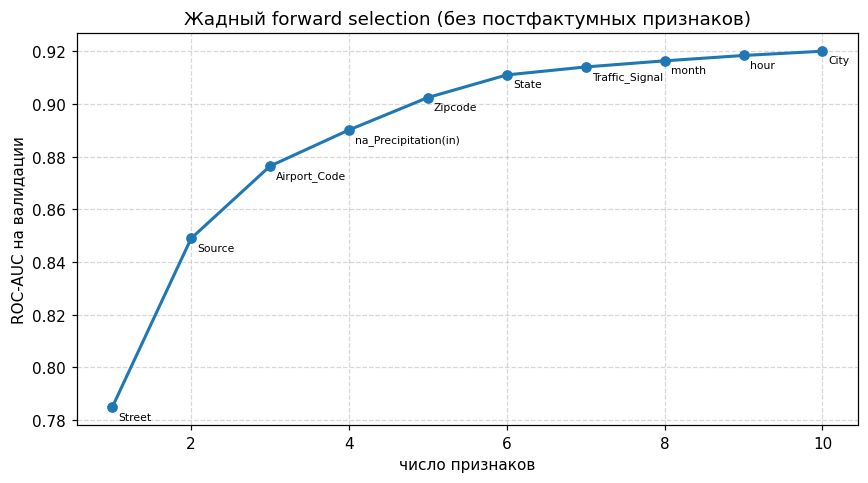

In [11]:
LEAKAGE = [c for c in LEAKAGE_CANDIDATES if c in feat_names]
print("постфактумные признаки (недоступны на момент ДТП):", LEAKAGE)

selected, fs_curve = [], []
if RUN_FORWARD:
    pool = [f for f in res["perm_auc"].sort_values(ascending=False).index
            if f not in LEAKAGE and f not in redundant and f not in quasi_cols][:12]
    print("пул для обёртки:", pool)

    fs_idx = rng.choice(len(Xtr), size=min(N_FS_TRAIN + N_FS_VALID, len(Xtr)), replace=False)
    Xfs, yfs = Xtr.iloc[fs_idx], ytr.iloc[fs_idx]
    Xf_tr, Xf_va, yf_tr, yf_va = train_test_split(Xfs, yfs, test_size=N_FS_VALID,
                                                  stratify=yfs, random_state=SEED)
    hgb = HistGradientBoostingClassifier(max_iter=120, learning_rate=0.1, max_leaf_nodes=31,
                                         early_stopping=False, random_state=SEED)
    t0 = time.time()
    best_auc, rest = 0.5, pool.copy()
    while rest and len(selected) < 12:
        scores = {}
        for f in rest:
            cols = selected + [f]
            m = clone(hgb).fit(Xf_tr[cols], yf_tr)
            scores[f] = roc_auc_score(yf_va, m.predict_proba(Xf_va[cols])[:, 1])
        f_best = max(scores, key=scores.get)
        gain = scores[f_best] - best_auc
        if selected and gain < 0.001:
            print(f"останов: {f_best} даёт всего +{gain:.4f}")
            break
        selected.append(f_best)
        rest.remove(f_best)
        best_auc = scores[f_best]
        fs_curve.append((len(selected), f_best, best_auc, gain))
        print(f"  +{f_best:22s} ROC-AUC = {best_auc:.4f} (+{gain:.4f})")
    print(f"forward selection: {time.time() - t0:.1f}s")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ks = [r[0] for r in fs_curve]
    aucs = [r[2] for r in fs_curve]
    ax.plot(ks, aucs, marker="o", lw=2)
    for k, f, a, _ in fs_curve:
        ax.annotate(f, (k, a), fontsize=7, xytext=(4, -8), textcoords="offset points")
    ax.set_xlabel("число признаков")
    ax.set_ylabel("ROC-AUC на валидации")
    ax.set_title("Жадный forward selection (без постфактумных признаков)")
    ax.grid(ls="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig("task1_forward.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    selected = [f for f in res["perm_auc"].sort_values(ascending=False).index
                if f not in LEAKAGE and f not in redundant and f not in quasi_cols][:10]
    print("обёртка выключена, беру top-10 по permutation:", selected)

,kind,tier,mean_rank,top10_votes,mi,iv,perm_auc,xgb_gain
feature,,,,,,,,
has_end,bin,утечка,3.8333,6,0.0540,0.7064,0.0449,0.5382
Street,cat,ядро,4.3333,5,0.0940,0.0599,0.0476,0.0754
duration_min,num,утечка,5.3333,6,0.0747,0.4914,0.0375,0.0175
Source,cat,ядро,5.6667,6,0.0535,0.7064,0.0034,0.0365
End_Lng,num,утечка,8.6667,5,0.0690,0.8334,0.0057,0.0110
Distance(mi),num,утечка,8.8333,3,0.0415,0.3844,0.0114,0.0100
Airport_Code,cat,ядро,9.8333,3,0.0494,0.1218,0.0025,0.0095
City,cat,ядро,10.1667,3,0.0561,0.1081,0.0018,0.0087
End_Lat,num,утечка,10.5000,2,0.0628,0.7926,0.0026,0.0088


распределение по группам:
tier
слабый             24
ядро               10
утечка              5
почти константа     5
дубль               2
резерв              2

согласованность методов (Spearman между рангами):


,mi,iv,auc_strength,xgb_gain,rf_impurity,perm_auc
mi,1.000,0.750,0.846,0.675,0.869,0.819
iv,0.750,1.000,0.759,0.627,0.728,0.703
auc_strength,0.846,0.759,1.000,0.768,0.922,0.826
xgb_gain,0.675,0.627,0.768,1.000,0.839,0.854
rf_impurity,0.869,0.728,0.922,0.839,1.000,0.920
perm_auc,0.819,0.703,0.826,0.854,0.920,1.000


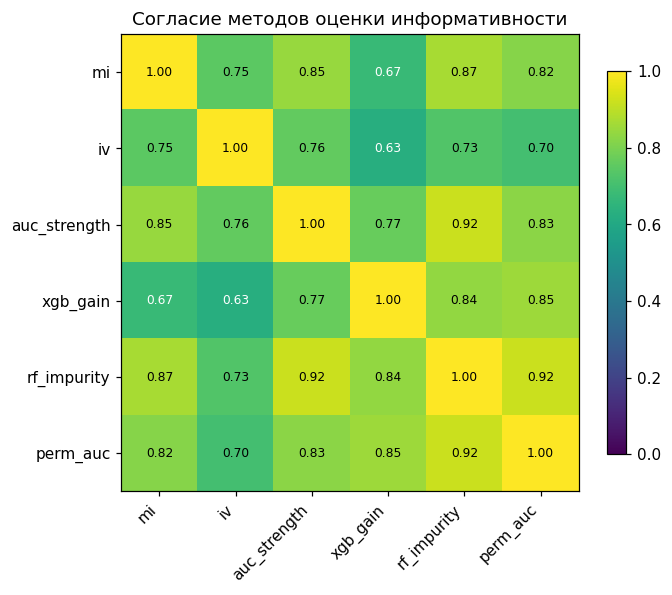

In [12]:
methods = ["mi", "iv", "auc_strength", "xgb_gain", "rf_impurity", "perm_auc"]
ranks = res[methods].rank(ascending=False, method="min")
res["mean_rank"] = ranks.mean(axis=1)
res["top10_votes"] = (ranks <= 10).sum(axis=1)
rank_corr = res[methods].corr(method="spearman")


def assign_tier(f):
    if f in LEAKAGE:
        return "утечка"
    if f in redundant:
        return "дубль"
    if f in selected:
        return "ядро"
    if f in quasi_cols:
        return "почти константа"
    if res.loc[f, "mean_rank"] <= 15:
        return "резерв"
    return "слабый"


res["tier"] = [assign_tier(f) for f in res.index]
res["redundant_of"] = pd.Series(redundant)
ranking = res.sort_values("mean_rank")
ranking.to_csv("task1_feature_ranking.csv", encoding="utf-8-sig")
display(ranking[["kind", "tier", "mean_rank", "top10_votes", "mi", "iv",
                 "perm_auc", "xgb_gain"]].head(25).round(4))

print("распределение по группам:")
print(res["tier"].value_counts().to_string())
print("\nсогласованность методов (Spearman между рангами):")
display(rank_corr.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(rank_corr.to_numpy(), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(methods)), methods, rotation=45, ha="right")
ax.set_yticks(np.arange(len(methods)), methods)
for i in range(len(methods)):
    for j in range(len(methods)):
        v = rank_corr.to_numpy()[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if v < 0.7 else "black", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Согласие методов оценки информативности")
plt.tight_layout()
plt.savefig("task1_method_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

,n_features,roc_auc,pr_auc,f1,bal_acc,fit_sec
set,,,,,,
KT3 baseline (15),15,0.7848,0.4428,0.2243,0.5569,1.0
KT4 selected (10),10,0.9234,0.7921,0.7215,0.8117,1.0
все без утечки,43,0.9301,0.8069,0.7337,0.8190,1.7
все признаки,48,0.9458,0.8299,0.7522,0.8355,1.8


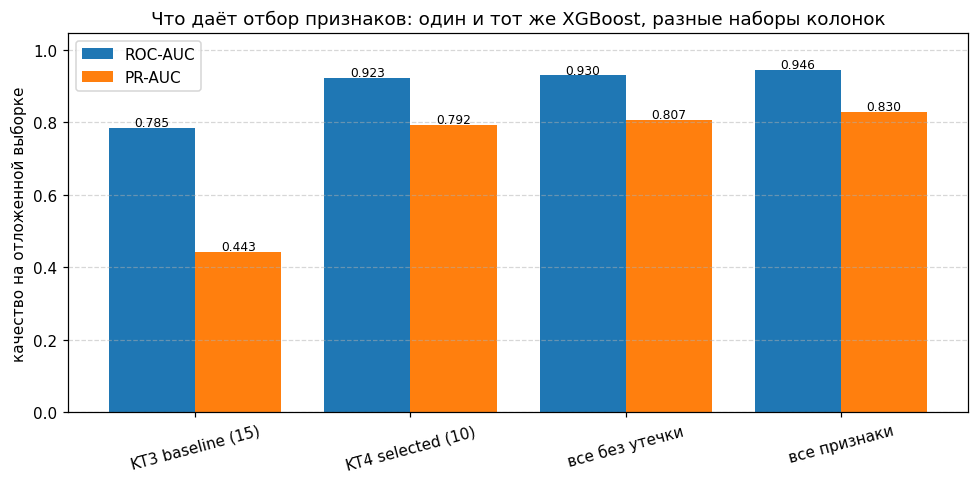

наборы признаков сохранены в task1_selected_features.json


In [13]:
kt3_cols = [c for c in KT3_FEATURES if c in feat_names]
feature_sets = {
    f"KT3 baseline ({len(kt3_cols)})": kt3_cols,
    f"KT4 selected ({len(selected)})": selected,
    "все без утечки": [f for f in feat_names if f not in LEAKAGE],
    "все признаки": feat_names,
}

rows = []
for name, cols in feature_sets.items():
    t0 = time.time()
    m = XGBClassifier(**xgb_params).fit(Xm[cols], ym)
    proba = m.predict_proba(Xp[cols])[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "set": name, "n_features": len(cols),
        "roc_auc": roc_auc_score(yp, proba),
        "pr_auc": average_precision_score(yp, proba),
        "f1": f1_score(yp, pred, zero_division=0),
        "bal_acc": balanced_accuracy_score(yp, pred),
        "fit_sec": round(time.time() - t0, 1),
    })
sets_df = pd.DataFrame(rows).set_index("set")
sets_df.to_csv("task1_feature_sets.csv", encoding="utf-8-sig")
display(sets_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
xpos = np.arange(len(sets_df))
ax.bar(xpos - 0.2, sets_df["roc_auc"], 0.4, label="ROC-AUC")
ax.bar(xpos + 0.2, sets_df["pr_auc"], 0.4, label="PR-AUC")
for i, (ra, pa) in enumerate(zip(sets_df["roc_auc"], sets_df["pr_auc"])):
    ax.text(i - 0.2, ra + 0.005, f"{ra:.3f}", ha="center", fontsize=8)
    ax.text(i + 0.2, pa + 0.005, f"{pa:.3f}", ha="center", fontsize=8)
ax.set_xticks(xpos, sets_df.index, rotation=15)
ax.set_ylim(0, max(sets_df["roc_auc"]) + 0.1)
ax.set_ylabel("качество на отложенной выборке")
ax.set_title("Что даёт отбор признаков: один и тот же XGBoost, разные наборы колонок")
ax.legend()
ax.grid(axis="y", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("task1_feature_sets.png", dpi=150, bbox_inches="tight")
plt.show()

json.dump({"kt3_baseline": kt3_cols, "selected": selected, "leakage": LEAKAGE,
           "redundant": redundant, "quasi_constant": quasi_cols, "constant": const_cols,
           "core_and_reserve": ranking.index[ranking["tier"].isin(["ядро", "резерв"])].tolist()},
          open("task1_selected_features.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("наборы признаков сохранены в task1_selected_features.json")

In [14]:
def fmt_top(col, n=6):
    s = res[col].sort_values(ascending=False).head(n)
    return ", ".join(f"{k} ({v:.3f})" for k, v in s.items())


delta_auc = sets_df.loc[f"KT4 selected ({len(selected)})", "roc_auc"] - sets_df.loc[f"KT3 baseline ({len(kt3_cols)})", "roc_auc"]
delta_all = sets_df.loc["все признаки", "roc_auc"] - sets_df.loc["все без утечки", "roc_auc"]
iv_strong = res.index[(res["iv"] >= 0.3) & (~res.index.isin(LEAKAGE))].tolist()

lines = [
    "Задание 1. Анализ информативности признаков (US Accidents, Severity >= 3).",
    f"Выборка: {len(df):,} аварий после дедупликации по group_id, доля тяжёлых {df['y'].mean():.3f}. "
    f"Признаков в анализе: {len(feat_names)} (числовых {len(num_features)}, бинарных {len(bin_features)}, категориальных {len(cat_features)}).",
    "",
    f"1. Аудит. Константы: {', '.join(const_cols) or 'нет'}. Почти константы (top-значение >= 99.5%): {', '.join(quasi_cols) or 'нет'}.",
    f"   Максимальный перекос пропусков между классами: "
    f"{audit.loc[audit['miss_gap_pp'].abs().idxmax(), 'feature']} "
    f"({audit['miss_gap_pp'].abs().max():.1f} п.п.), поэтому индикаторы пропусков добавлены как отдельные признаки.",
    "",
    f"2. Фильтры. Топ по mutual information: {fmt_top('mi')}.",
    f"   Топ по IV: {fmt_top('iv')}.",
    f"   Топ по одиночному ROC-AUC: {fmt_top('auc_strength')}.",
    f"   Признаков с IV >= 0.3 вне списка утечки: {len(iv_strong)} ({', '.join(iv_strong[:10])}).",
    "",
    f"3. Избыточность. Пар с |Spearman| >= 0.9: {len(pairs)}, к удалению как дубли отобрано {len(redundant)}: "
    f"{', '.join(list(redundant)[:10])}.",
    "",
    f"4. Модельные оценки. Топ по permutation importance (падение ROC-AUC): {fmt_top('perm_auc')}.",
]
if "drop_col_auc" in res.columns:
    lines.append(f"   Drop-column по top-10: {fmt_top('drop_col_auc')}.")
lines += [
    f"   Согласие методов (Spearman MI vs permutation): {rank_corr.loc['mi', 'perm_auc']:.2f}, "
    f"impurity леса vs permutation: {rank_corr.loc['rf_impurity', 'perm_auc']:.2f}.",
    "",
    f"5. Постфактумные признаки: {', '.join(LEAKAGE)}. "
    f"Их суммарный вклад в ROC-AUC (все признаки минус все без утечки): {delta_all:+.4f}.",
    "",
    f"6. Обёртка. Отобрано {len(selected)} признаков: {', '.join(selected)}.",
]
if fs_curve:
    lines.append(f"   ROC-AUC на валидации после последнего шага: {fs_curve[-1][2]:.4f}.")
lines += [
    "",
    "7. Проверка на модели (один и тот же XGBoost, отложенная выборка):",
]
for name, r in sets_df.iterrows():
    lines.append(f"   {name:24s} ROC-AUC {r['roc_auc']:.4f}, PR-AUC {r['pr_auc']:.4f}, "
                 f"F1@0.5 {r['f1']:.4f}, bal.acc {r['bal_acc']:.4f}")
lines += [
    f"   Прирост отобранного набора относительно базового из КТ3: {delta_auc:+.4f} ROC-AUC.",
    "",
    "Артефакты: task1_audit.csv, task1_filters.csv, task1_feature_ranking.csv, "
    "task1_feature_sets.csv, task1_selected_features.json и графики task1_*.png.",
]
summary = "\n".join(lines)
print(summary)
with open("task1_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)

Задание 1. Анализ информативности признаков (US Accidents, Severity >= 3).
Выборка: 443,663 аварий после дедупликации по group_id, доля тяжёлых 0.197. Признаков в анализе: 48 (числовых 15, бинарных 19, категориальных 14).

1. Аудит. Константы: Turning_Loop, Country. Почти константы (top-значение >= 99.5%): Bump, Give_Way, Roundabout, No_Exit, Traffic_Calming.
   Максимальный перекос пропусков между классами: End_Lng (40.1 п.п.), поэтому индикаторы пропусков добавлены как отдельные признаки.

2. Фильтры. Топ по mutual information: Street (0.094), Zipcode (0.084), duration_min (0.075), End_Lng (0.069), Start_Lng (0.064), End_Lat (0.063).
   Топ по IV: End_Lng (0.833), End_Lat (0.793), has_end (0.706), Source (0.706), duration_min (0.491), Distance(mi) (0.384).
   Топ по одиночному ROC-AUC: Street (0.277), Zipcode (0.254), City (0.220), Airport_Code (0.214), Source (0.202), has_end (0.202).
   Признаков с IV >= 0.3 вне списка утечки: 1 (Source).

3. Избыточность. Пар с |Spearman| >= 0.9: 